# PROJECT UTS PEMBELAJARAN MESIN 2026
* Nama  : Muhammad Hafizh Wijdan
* NIM   : 202431005
* Kelas : TI-G
* Tugas : Regresi Linier dan K-Nearest Neighbors (KNN) pada Dataset Diabetes


In [1]:
# Muhammad Hafizh Wijdan - 202431005

# library buat manipulasi dataframe dan array numerik
import pandas as pd
import numpy as np

# library buat bikin grafik dan visualisasi data
import matplotlib.pyplot as plt

# modul sklearn buat split data latih dan data uji
from sklearn.model_selection import train_test_split

# modul buat ubah kategori ke angka dan standarisasi nilai
from sklearn.preprocessing import StandardScaler, LabelEncoder

# algoritma regresi linier dan k-nearest neighbors
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

# kumpulan fungsi buat hitung akurasi, confusion matrix, dan error
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

# pasang tema visualisasi biar grafiknya rapi ada grid
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Semua library berhasil dimuat dan siap digunakan.")


Semua library berhasil dimuat dan siap digunakan.


In [2]:
# Muhammad Hafizh Wijdan - 202431005

# baca file csv dataset diabetes
df = pd.read_csv('02_diabetes.csv')

# cek berapa jumlah baris dan kolom datanya
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")

# lihat 5 baris pertama data buat tahu isinya
print("--- 5 Baris Teratas ---")
display(df.head())

# cek tipe data tiap kolom dan pastikan kebaca semua
print("\n--- Informasi Tipe Data ---")
df.info()


Ukuran dataset: 100000 baris, 9 kolom

--- 5 Baris Teratas ---


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



--- Informasi Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [3]:
# Muhammad Hafizh Wijdan - 202431005

# hitung apakah ada nilai kosong atau null di setiap kolom
print("--- Cek Missing Values ---")
print(df.isnull().sum())

# hitung ada berapa baris data yang duplikat
print(f"\nJumlah data duplikat: {df.duplicated().sum()} baris ({df.duplicated().sum() / len(df) * 100:.2f}%)")

# lihat statistik deskriptif buat tahu rata-rata, min, dan max tiap fitur
print("\n--- Ringkasan Statistik Data Numerik ---")
display(df.describe())


--- Cek Missing Values ---
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Jumlah data duplikat: 3854 baris (3.85%)

--- Ringkasan Statistik Data Numerik ---


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


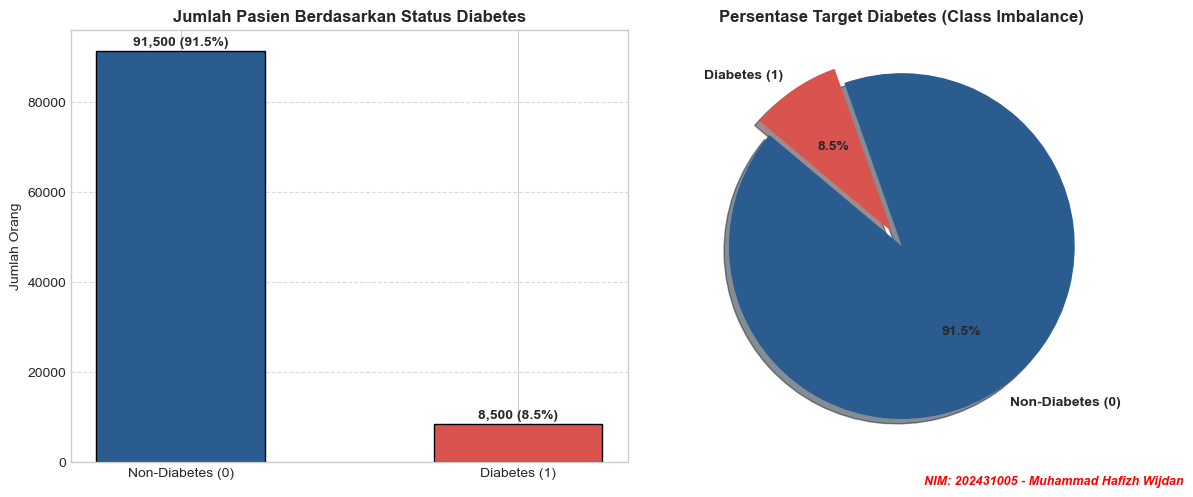

Hasil distribusi target: 91,500 orang sehat (0) dan 8,500 orang diabetes (1)


In [4]:
# Muhammad Hafizh Wijdan - 202431005

# siapkan area canvas dengan 2 kolom grafik
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# hitung jumlah masing-masing kelas target diabetes (0 dan 1)
counts = df['diabetes'].value_counts()
labels = ['Non-Diabetes (0)', 'Diabetes (1)']
colors = ['#2b5c8f', '#d9534f']

# buat diagram batang di sebelah kiri
axes[0].bar(labels, counts.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Jumlah Pasien Berdasarkan Status Diabetes', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Orang')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# pasang angka persentase di atas batang grafik
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1200, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# buat diagram lingkaran (pie chart) di sebelah kanan
axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=(0, 0.1), shadow=True,
            textprops={'fontsize': 10, 'fontweight': 'bold'})
axes[1].set_title('Persentase Target Diabetes (Class Imbalance)', fontsize=12, fontweight='bold')

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()

print(f"Hasil distribusi target: {counts[0]:,} orang sehat (0) dan {counts[1]:,} orang diabetes (1)")


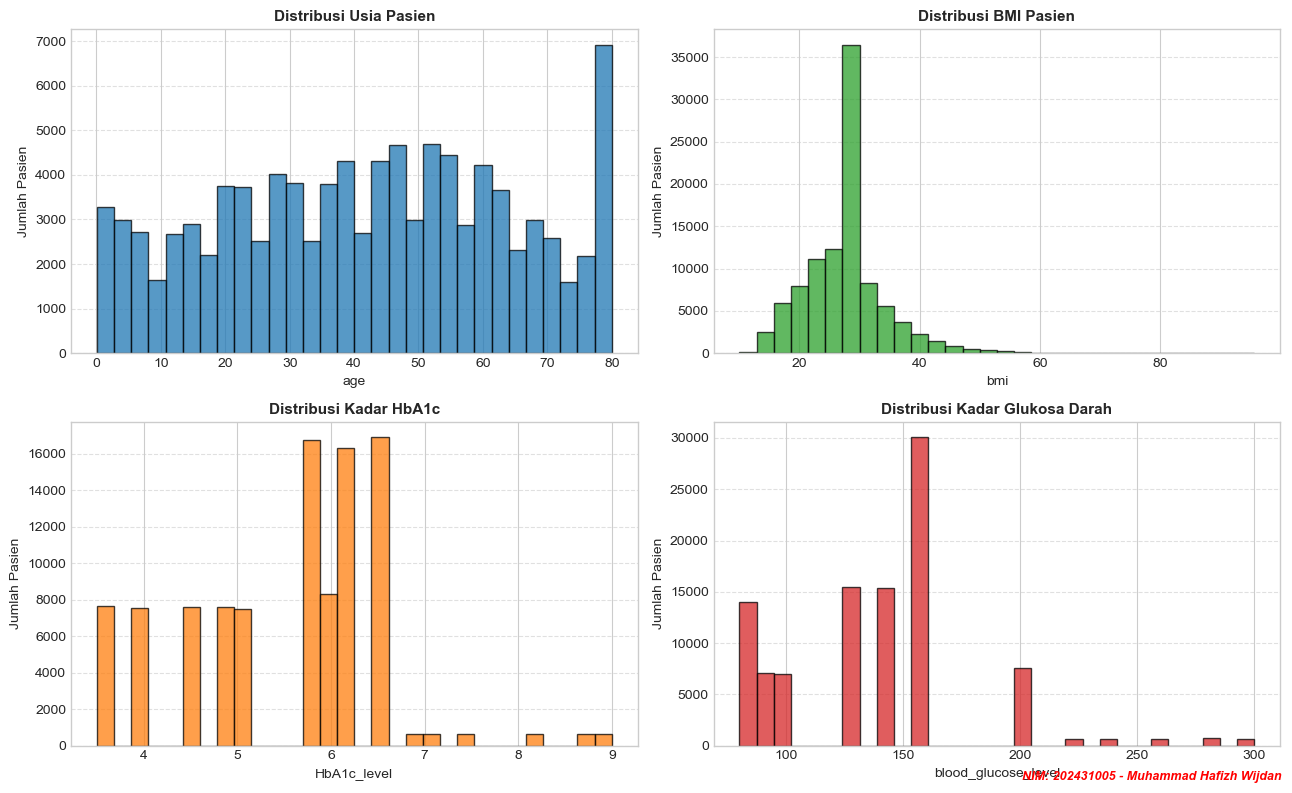

In [5]:
# Muhammad Hafizh Wijdan - 202431005

# siapkan canvas 2 baris x 2 kolom buat tampilin 4 histogram
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# daftar nama kolom dan judul grafik masing-masing
features_plot = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
titles = ['Distribusi Usia Pasien', 'Distribusi BMI Pasien', 
          'Distribusi Kadar HbA1c', 'Distribusi Kadar Glukosa Darah']
colors_hist = ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']

# looping buat gambar histogram di setiap subplot
for ax, feat, title, col in zip(axes.flatten(), features_plot, titles, colors_hist):
    ax.hist(df[feat], bins=30, color=col, edgecolor='black', alpha=0.75)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Jumlah Pasien')
    ax.grid(axis='y', linestyle='--', alpha=0.6)

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()


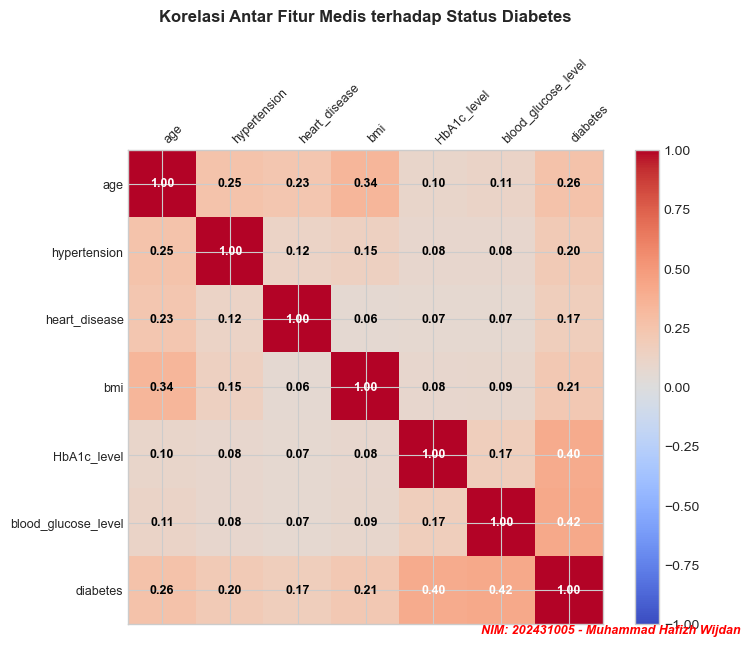

--- Urutan Korelasi Fitur terhadap Diabetes ---
diabetes               1.000000
blood_glucose_level    0.419558
HbA1c_level            0.400660
age                    0.258008
bmi                    0.214357
hypertension           0.197823
heart_disease          0.171727
Name: diabetes, dtype: float64


In [6]:
# Muhammad Hafizh Wijdan - 202431005

# pilih fitur numerik buat dihitung nilai korelasinya
num_cols = ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']
corr_matrix = df[num_cols].corr()

# bikin canvas heatmap korelasi
fig, ax = plt.subplots(figsize=(8, 6.5))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

# pasang nama kolom pada sumbu x dan y
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='left', fontsize=9)
ax.set_yticklabels(num_cols, fontsize=9)

# tuliskan angka korelasi di setiap kotak heatmap
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.4 else 'black', fontweight='bold', fontsize=9)

ax.set_title('Korelasi Antar Fitur Medis terhadap Status Diabetes', fontsize=12, fontweight='bold', pad=25)

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()

# cetak urutan korelasi tertinggi ke terendah terhadap diabetes
print("--- Urutan Korelasi Fitur terhadap Diabetes ---")
print(corr_matrix['diabetes'].sort_values(ascending=False))


In [7]:
# Muhammad Hafizh Wijdan - 202431005

# 1. bersihkan data duplikat biar gak bocor pas testing
total_awal = len(df)
df_clean = df.drop_duplicates().copy()
print(f"Data duplikat yang dibuang: {total_awal - len(df_clean)} baris")

# 2. buang baris dengan gender 'Other' karena cuma 18 baris
df_clean = df_clean[df_clean['gender'] != 'Other'].copy()
print(f"Sisa data setelah filter anomali: {df_clean.shape[0]} baris")

# 3. ubah jenis kelamin jadi angka: Female=0, Male=1
le_gender = LabelEncoder()
df_clean['gender'] = le_gender.fit_transform(df_clean['gender'])

# 4. ubah kolom riwayat merokok jadi one-hot encoding
df_encoded = pd.get_dummies(df_clean, columns=['smoking_history'], drop_first=True)

print(f"Bentuk data setelah encoding: {df_encoded.shape[0]} baris dan {df_encoded.shape[1]} kolom")
print("\n--- 5 Baris Data Bersih ---")
display(df_encoded.head())


Data duplikat yang dibuang: 3854 baris
Sisa data setelah filter anomali: 96128 baris
Bentuk data setelah encoding: 96128 baris dan 13 kolom

--- 5 Baris Data Bersih ---


,gender,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,0,80.0,0,1,25.19,6.6,140,0,False,False,False,True,False
1,0,54.0,0,0,27.32,6.6,80,0,False,False,False,False,False
2,1,28.0,0,0,27.32,5.7,158,0,False,False,False,True,False
3,0,36.0,0,0,23.45,5.0,155,0,True,False,False,False,False
4,1,76.0,1,1,20.14,4.8,155,0,True,False,False,False,False


In [8]:
# Muhammad Hafizh Wijdan - 202431005

# pisahkan variabel penjelas (X) dan label tujuan (y)
X = df_encoded.drop(columns=['diabetes'])
y = df_encoded['diabetes']

# bagi data jadi data latih 80% dan data uji 20% secara proporsional
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# samakan skala semua fitur pakai StandardScaler biar adil buat KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data latih (Train) : {X_train.shape[0]:,} baris")
print(f"Data uji (Test)    : {X_test.shape[0]:,} baris")
print(f"Jumlah fitur (X)   : {X_train.shape[1]} kolom")
print(f"Proporsi kelas latih: Non-Diabetes = {(y_train==0).sum()}, Diabetes = {(y_train==1).sum()}")
print(f"Proporsi kelas uji  : Non-Diabetes = {(y_test==0).sum()}, Diabetes = {(y_test==1).sum()}")


Data latih (Train) : 76,902 baris
Data uji (Test)    : 19,226 baris
Jumlah fitur (X)   : 12 kolom
Proporsi kelas latih: Non-Diabetes = 70116, Diabetes = 6786
Proporsi kelas uji  : Non-Diabetes = 17530, Diabetes = 1696


--- Hasil Evaluasi Regresi Linier (Target: Glukosa) ---
R-squared (R2 Score) : 0.0501
Mean Absolute Error  : 30.9491 mg/dL
Mean Squared Error   : 1598.9669
Root MSE (RMSE)      : 39.9871 mg/dL


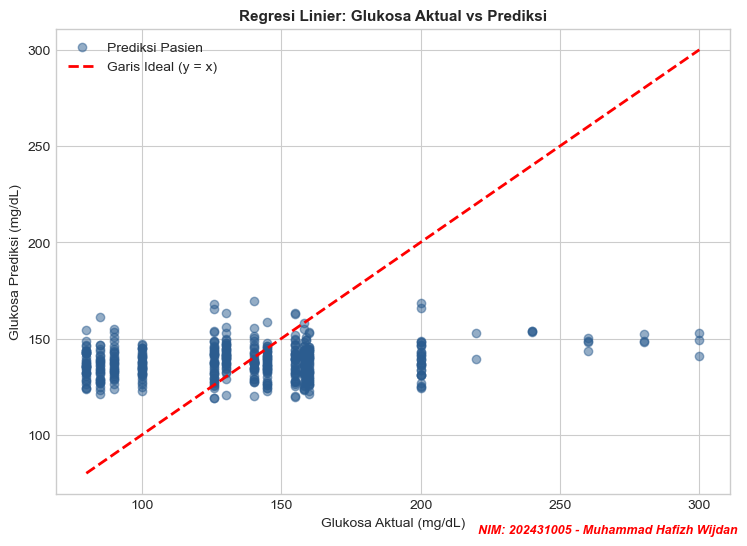

In [9]:
# Muhammad Hafizh Wijdan - 202431005

# pisahkan fitur input buat prediksi kadar glukosa darah kontinu
features_reg = [c for c in X.columns if c != 'blood_glucose_level']
X_reg_tr = X_train[features_reg]
X_reg_te = X_test[features_reg]
y_reg_tr = X_train['blood_glucose_level']
y_reg_te = X_test['blood_glucose_level']

# standarisasi input fitur regresi
scaler_reg = StandardScaler()
X_reg_tr_sc = scaler_reg.fit_transform(X_reg_tr)
X_reg_te_sc = scaler_reg.transform(X_reg_te)

# latih model regresi linier pakai fit()
lr_cont = LinearRegression()
lr_cont.fit(X_reg_tr_sc, y_reg_tr)

# tebak nilai glukosa data uji pakai predict()
y_reg_pred = lr_cont.predict(X_reg_te_sc)

# hitung metrik evaluasi regresi: r2, mae, mse, rmse
r2_reg = r2_score(y_reg_te, y_reg_pred)
mae_reg = mean_absolute_error(y_reg_te, y_reg_pred)
mse_reg = mean_squared_error(y_reg_te, y_reg_pred)
rmse_reg = np.sqrt(mse_reg)

print("--- Hasil Evaluasi Regresi Linier (Target: Glukosa) ---")
print(f"R-squared (R2 Score) : {r2_reg:.4f}")
print(f"Mean Absolute Error  : {mae_reg:.4f} mg/dL")
print(f"Mean Squared Error   : {mse_reg:.4f}")
print(f"Root MSE (RMSE)      : {rmse_reg:.4f} mg/dL")

# gambar scatter plot nilai riil vs hasil tebakan model
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sample_plot = np.random.RandomState(42).choice(len(y_reg_te), 500, replace=False)
ax.scatter(y_reg_te.iloc[sample_plot], y_reg_pred[sample_plot], alpha=0.5, color='#2b5c8f', label='Prediksi Pasien')
ax.plot([y_reg_te.min(), y_reg_te.max()], [y_reg_te.min(), y_reg_te.max()], 'r--', lw=2, label='Garis Ideal (y = x)')
ax.set_title('Regresi Linier: Glukosa Aktual vs Prediksi', fontsize=11, fontweight='bold')
ax.set_xlabel('Glukosa Aktual (mg/dL)')
ax.set_ylabel('Glukosa Prediksi (mg/dL)')
ax.legend()

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()


In [10]:
# Muhammad Hafizh Wijdan - 202431005

# latih regresi linier langsung ke target diabetes 0 atau 1
lr_clf = LinearRegression()
lr_clf.fit(X_train_scaled, y_train)

# hasil tebakan berupa angka kontinu
y_pred_lr_cont = lr_clf.predict(X_test_scaled)

# bulatkan kalau >= 0.5 jadi diabetes (1), selain itu 0
y_pred_lr_bin = (y_pred_lr_cont >= 0.5).astype(int)

# hitung performa akurasi, presisi, recall, dan f1
acc_lr = accuracy_score(y_test, y_pred_lr_bin)
prec_lr = precision_score(y_test, y_pred_lr_bin, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr_bin, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr_bin, zero_division=0)

print("--- Hasil Klasifikasi Regresi Linier (Threshold 0.5) ---")
print(f"Akurasi   : {acc_lr * 100:.2f}%")
print(f"Presisi   : {prec_lr * 100:.2f}%")
print(f"Recall    : {rec_lr * 100:.2f}%")
print(f"F1-Score  : {f1_lr * 100:.2f}%\n")

print("--- Laporan Klasifikasi Rinci ---")
print(classification_report(y_test, y_pred_lr_bin, target_names=['Non-Diabetes (0)', 'Diabetes (1)']))


--- Hasil Klasifikasi Regresi Linier (Threshold 0.5) ---
Akurasi   : 93.96%
Presisi   : 99.08%
Recall    : 31.84%
F1-Score  : 48.19%

--- Laporan Klasifikasi Rinci ---
                  precision    recall  f1-score   support

Non-Diabetes (0)       0.94      1.00      0.97     17530
    Diabetes (1)       0.99      0.32      0.48      1696

        accuracy                           0.94     19226
       macro avg       0.96      0.66      0.72     19226
    weighted avg       0.94      0.94      0.93     19226



K =  1 -> Akurasi Latih: 99.99%, Akurasi Uji: 93.60%
K =  3 -> Akurasi Latih: 96.98%, Akurasi Uji: 94.95%
K =  5 -> Akurasi Latih: 96.43%, Akurasi Uji: 95.03%
K =  7 -> Akurasi Latih: 96.11%, Akurasi Uji: 94.85%
K =  9 -> Akurasi Latih: 95.87%, Akurasi Uji: 94.92%
K = 11 -> Akurasi Latih: 95.64%, Akurasi Uji: 95.00%
K = 15 -> Akurasi Latih: 95.31%, Akurasi Uji: 94.83%

Nilai K paling optimal: K = 5 dengan akurasi uji = 95.03%


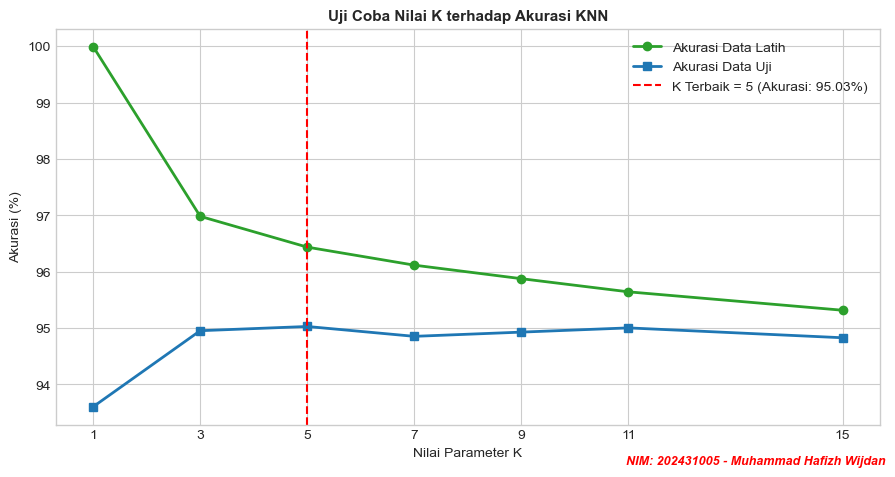

In [11]:
# Muhammad Hafizh Wijdan - 202431005

# daftar angka k ganjil yang mau dites
k_range = [1, 3, 5, 7, 9, 11, 15]
train_acc_list = []
test_acc_list = []

# ambil subsample buat uji coba kurva biar proses komputasi cepet
sub_idx_tr = np.random.RandomState(42).choice(len(X_train_scaled), 15000, replace=False)
sub_idx_te = np.random.RandomState(42).choice(len(X_test_scaled), 4000, replace=False)

# lakukan perulangan melatih model untuk setiap nilai k
for k in k_range:
    knn_exp = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_exp.fit(X_train_scaled[sub_idx_tr], y_train.iloc[sub_idx_tr])
    train_acc = accuracy_score(y_train.iloc[sub_idx_tr], knn_exp.predict(X_train_scaled[sub_idx_tr]))
    test_acc = accuracy_score(y_test.iloc[sub_idx_te], knn_exp.predict(X_test_scaled[sub_idx_te]))
    train_acc_list.append(train_acc)
    test_acc_list.append(test_acc)
    print(f"K = {k:2d} -> Akurasi Latih: {train_acc*100:.2f}%, Akurasi Uji: {test_acc*100:.2f}%")

# cari nilai k yang ngasih akurasi uji paling tinggi
best_k = k_range[np.argmax(test_acc_list)]
print(f"\nNilai K paling optimal: K = {best_k} dengan akurasi uji = {max(test_acc_list)*100:.2f}%")

# plot grafik perbandingan nilai k
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(k_range, [a * 100 for a in train_acc_list], 'o-', label='Akurasi Data Latih', color='#2ca02c', lw=2)
ax.plot(k_range, [a * 100 for a in test_acc_list], 's-', label='Akurasi Data Uji', color='#1f77b4', lw=2)
ax.axvline(best_k, color='red', linestyle='--', label=f'K Terbaik = {best_k} (Akurasi: {max(test_acc_list)*100:.2f}%)')
ax.set_title('Uji Coba Nilai K terhadap Akurasi KNN', fontsize=11, fontweight='bold')
ax.set_xlabel('Nilai Parameter K')
ax.set_ylabel('Akurasi (%)')
ax.set_xticks(k_range)
ax.legend()

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()


=== HASIL AKURASI OLAHAN DATA MODEL KNN (K=7) ===
Akurasi Final KNN : 95.89%
Presisi           : 90.02%
Recall            : 60.08%
F1-Score          : 72.07%

--- Laporan Klasifikasi KNN Lengkap ---
                  precision    recall  f1-score   support

Non-Diabetes (0)       0.96      0.99      0.98     17530
    Diabetes (1)       0.90      0.60      0.72      1696

        accuracy                           0.96     19226
       macro avg       0.93      0.80      0.85     19226
    weighted avg       0.96      0.96      0.96     19226



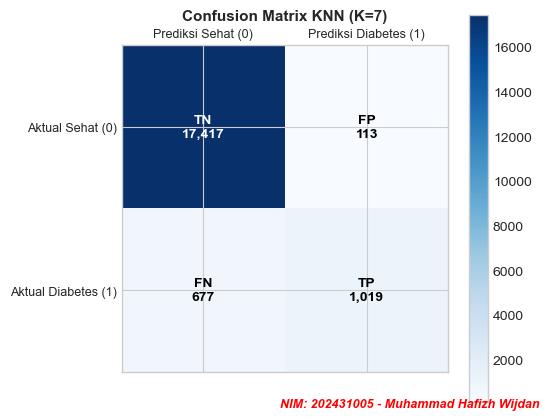

In [12]:
# Muhammad Hafizh Wijdan - 202431005

# pasang k terbaik k=7 dan latih model ke semua data latih
best_k_final = 7
knn_final = KNeighborsClassifier(n_neighbors=best_k_final, metric='euclidean', n_jobs=-1)
knn_final.fit(X_train_scaled, y_train)

# uji tebakan model pada data uji
y_pred_knn = knn_final.predict(X_test_scaled)

# hitung metrik akurasi hasil olahan data
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, zero_division=0)
rec_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
cm_knn = confusion_matrix(y_test, y_pred_knn)

print(f"=== HASIL AKURASI OLAHAN DATA MODEL KNN (K={best_k_final}) ===")
print(f"Akurasi Final KNN : {acc_knn * 100:.2f}%")
print(f"Presisi           : {prec_knn * 100:.2f}%")
print(f"Recall            : {rec_knn * 100:.2f}%")
print(f"F1-Score          : {f1_knn * 100:.2f}%\n")

print("--- Laporan Klasifikasi KNN Lengkap ---")
print(classification_report(y_test, y_pred_knn, target_names=['Non-Diabetes (0)', 'Diabetes (1)']))

# gambar grafik tabel confusion matrix
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cax = ax.matshow(cm_knn, cmap='Blues')
fig.colorbar(cax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Prediksi Sehat (0)', 'Prediksi Diabetes (1)'], fontsize=9)
ax.set_yticklabels(['Aktual Sehat (0)', 'Aktual Diabetes (1)'], fontsize=9)

labels_cm = [
    [f"TN\n{cm_knn[0, 0]:,}", f"FP\n{cm_knn[0, 1]:,}"],
    [f"FN\n{cm_knn[1, 0]:,}", f"TP\n{cm_knn[1, 1]:,}"]
]

for i in range(2):
    for j in range(2):
        ax.text(j, i, labels_cm[i][j], ha='center', va='center',
                color='white' if cm_knn[i, j] > cm_knn.max() / 2 else 'black',
                fontsize=10, fontweight='bold')

ax.set_title(f'Confusion Matrix KNN (K={best_k_final})', fontsize=11, fontweight='bold', pad=18)

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()


In [13]:
# Muhammad Hafizh Wijdan - 202431005

# latih model knn regressor buat perbandingan kasus kontinu
knnr = KNeighborsRegressor(n_neighbors=7, n_jobs=-1)
knnr.fit(X_reg_tr_sc[sub_idx_tr], y_reg_tr.iloc[sub_idx_tr])

# tebak nilai glukosa kontinu pakai knn
y_knnr_pred = knnr.predict(X_reg_te_sc)

# hitung metrik r2, mae, dan rmse pada knn regresi
r2_knnr = r2_score(y_reg_te, y_knnr_pred)
mae_knnr = mean_absolute_error(y_reg_te, y_knnr_pred)
rmse_knnr = np.sqrt(mean_squared_error(y_reg_te, y_knnr_pred))

# susun ke tabel komparasi kasus regresi
df_comp_reg = pd.DataFrame({
    'Metrik': ['R-squared (R2)', 'MAE (mg/dL)', 'RMSE (mg/dL)'],
    'Regresi Linier': [f"{r2_reg:.4f}", f"{mae_reg:.4f}", f"{rmse_reg:.4f}"],
    'KNN Regressor (K=7)': [f"{r2_knnr:.4f}", f"{mae_knnr:.4f}", f"{rmse_knnr:.4f}"]
})

print("--- Perbandingan Kasus Regresi Nilai Kontinu ---")
display(df_comp_reg)


--- Perbandingan Kasus Regresi Nilai Kontinu ---


,Metrik,Regresi Linier,KNN Regressor (K=7)
0,R-squared (R2),0.0501,-0.0414
1,MAE (mg/dL),30.9491,33.0544
2,RMSE (mg/dL),39.9871,41.8678


--- Tabel Perbandingan Metrik Klasifikasi ---


,Metrik Evaluasi,Regresi Linier (Threshold 0.5),K-Nearest Neighbors (K=7)
0,Akurasi (%),93.961302,95.890981
1,Presisi (%),99.082569,90.017668
2,Recall (%),31.839623,60.082547
3,F1-Score (%),48.192771,72.065064


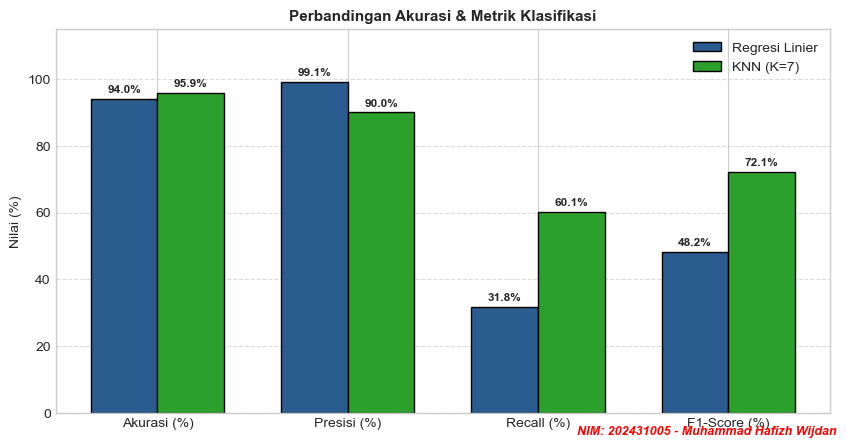

In [14]:
# Muhammad Hafizh Wijdan - 202431005

# buat tabel rekap perbandingan performa klasifikasi
df_comparison_clf = pd.DataFrame({
    'Metrik Evaluasi': ['Akurasi (%)', 'Presisi (%)', 'Recall (%)', 'F1-Score (%)'],
    'Regresi Linier (Threshold 0.5)': [acc_lr * 100, prec_lr * 100, rec_lr * 100, f1_lr * 100],
    'K-Nearest Neighbors (K=7)': [acc_knn * 100, prec_knn * 100, rec_knn * 100, f1_knn * 100]
})

print("--- Tabel Perbandingan Metrik Klasifikasi ---")
display(df_comparison_clf)

# buat diagram batang berdampingan
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x_pos = np.arange(len(df_comparison_clf))
width = 0.35

rects1 = ax.bar(x_pos - width/2, df_comparison_clf['Regresi Linier (Threshold 0.5)'], width,
                label='Regresi Linier', color='#2b5c8f', edgecolor='black')
rects2 = ax.bar(x_pos + width/2, df_comparison_clf['K-Nearest Neighbors (K=7)'], width,
                label='KNN (K=7)', color='#2ca02c', edgecolor='black')

ax.set_ylabel('Nilai (%)')
ax.set_title('Perbandingan Akurasi & Metrik Klasifikasi', fontsize=11, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(df_comparison_clf['Metrik Evaluasi'])
ax.set_ylim(0, 115)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# pasang angka persentase di atas setiap batang
for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# watermark nim pada grafik
plt.figtext(0.99, 0.015, 'NIM: 202431005 - Muhammad Hafizh Wijdan', ha='right', va='bottom', fontsize=9, color='#FF0000', fontstyle='italic', weight='bold')

plt.tight_layout()
plt.show()


In [15]:
# Muhammad Hafizh Wijdan - 202431005

# fungsi buat tes prediksi data pasien baru
def tes_prediksi_pasien(profil_dict, nomor_pasien):
    # bikin dataframe 1 baris sesuai urutan kolom X
    df_p = pd.DataFrame([profil_dict])[X.columns]
    # lakukan scaling yang sama persis kayak data train
    df_p_scaled = scaler.transform(df_p)
    
    # tebak status pakai knn
    pred = knn_final.predict(df_p_scaled)[0]
    prob = knn_final.predict_proba(df_p_scaled)[0]
    
    status_str = "POSITIF DIABETES (1)" if pred == 1 else "NEGATIF DIABETES (0)"
    confidence = prob[pred] * 100
    
    print(f"=== HASIL PREDIKSI PASIEN #{nomor_pasien} ===")
    print(f"Usia: {profil_dict['age']} th | BMI: {profil_dict['bmi']} | HbA1c: {profil_dict['HbA1c_level']}% | Glukosa: {profil_dict['blood_glucose_level']} mg/dL")
    print(f">> Hasil Prediksi KNN : {status_str}")
    print(f">> Tingkat Keyakinan  : {confidence:.2f}%\n")

# data pasien 1: kondisi sehat normal
pasien_sehat = {
    'gender': 0, 'age': 25.0, 'hypertension': 0, 'heart_disease': 0,
    'bmi': 21.5, 'HbA1c_level': 4.8, 'blood_glucose_level': 95,
    'smoking_history_current': 0, 'smoking_history_ever': 0,
    'smoking_history_former': 0, 'smoking_history_never': 1, 'smoking_history_not current': 0
}

# data pasien 2: lansia dengan gula darah dan hba1c tinggi
pasien_risiko = {
    'gender': 1, 'age': 65.0, 'hypertension': 1, 'heart_disease': 1,
    'bmi': 34.2, 'HbA1c_level': 7.9, 'blood_glucose_level': 220,
    'smoking_history_current': 1, 'smoking_history_ever': 0,
    'smoking_history_former': 0, 'smoking_history_never': 0, 'smoking_history_not current': 0
}

# jalankan fungsi prediksi
tes_prediksi_pasien(pasien_sehat, 1)
tes_prediksi_pasien(pasien_risiko, 2)


=== HASIL PREDIKSI PASIEN #1 ===
Usia: 25.0 th | BMI: 21.5 | HbA1c: 4.8% | Glukosa: 95 mg/dL
>> Hasil Prediksi KNN : NEGATIF DIABETES (0)
>> Tingkat Keyakinan  : 100.00%

=== HASIL PREDIKSI PASIEN #2 ===
Usia: 65.0 th | BMI: 34.2 | HbA1c: 7.9% | Glukosa: 220 mg/dL
>> Hasil Prediksi KNN : POSITIF DIABETES (1)
>> Tingkat Keyakinan  : 85.71%

